# Figure 4C–D - Principal functional gradient


In [1]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import pandas as pd
base_path = next(
    p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
    if (p / "CODE").is_dir() and (p / "DATA").is_dir()
)
import os
sys.path.insert(0, str(Path(base_path) / 'CODE'))


In [2]:
AX_GREY = "#757575"

figsize = (15, 10) # (7, 6) (14, 8)
TITLE_FS = 16      
LABEL_FS = 32       
TICK_FS  = 35     
MARKERS = 100
LINE = 4
ALPHA = 0.5

LABEL_FS = 35
TICK_FS = 35
figsize = (13, 9)
output_path = f"{base_path}/FIGURES/main/Fig_4"
os.makedirs(output_path, exist_ok=True)

## 4C: primary functional gradient at rest for 3 datasets

In [3]:
# Plotting function

def plot_zscored_curve(
    ax,
    pred_path,
    color,
    label
):
    preds = pd.read_csv(pred_path)

    mu = preds["predicted"].mean()
    sigma = preds["predicted"].std(ddof=1)

    z_pred = (
        preds["predicted"] - mu
    ) / sigma

    z_low = (
        preds["conf.low"] - mu
    ) / sigma

    z_high = (
        preds["conf.high"] - mu
    ) / sigma

    ax.plot(
        preds["x"],
        z_pred,
        color=color,
        linewidth=LINE,
        zorder=2,
        label=label
    )

    if {"conf.low", "conf.high"}.issubset(preds.columns):

        ax.fill_between(
            preds["x"],
            z_low,
            z_high,
            color=color,
            alpha=0.15,
            zorder=0
        )

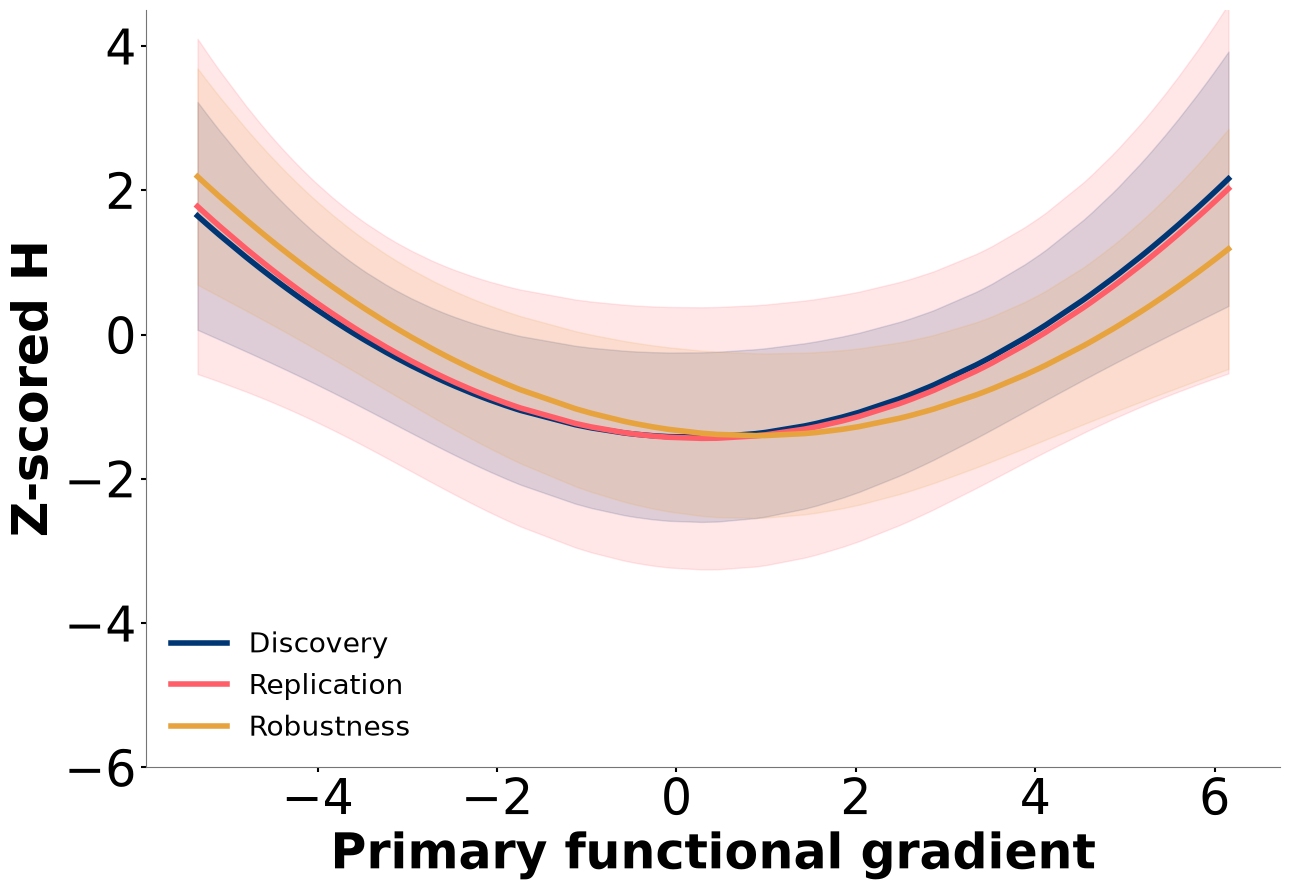

In [4]:
fig, ax = plt.subplots(figsize=figsize)


plot_zscored_curve(
    ax=ax,
    pred_path=f"{base_path}/RESULTS/discovery_dataset/models/margulies_model_quad.csv",
    color="#003674",
    label="Discovery"
)


plot_zscored_curve(
    ax=ax,
    pred_path=f"{base_path}/RESULTS/replication_dataset/models/margulies_model_quad.csv",
    color="#ff5e69",
    label="Replication"
)


plot_zscored_curve(
    ax=ax,
    pred_path=f"{base_path}/RESULTS/robustness_dataset/models/margulies_model_quad.csv",
    color="#E7A33E",
    label="Robustness"
)


# Aesthetics

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.spines["left"].set_color(AX_GREY)
ax.spines["bottom"].set_color(AX_GREY)

ax.set_xlabel(
    "Primary functional gradient",
    fontsize=LABEL_FS,
    fontweight="bold"
)

ax.set_ylabel(
    "Z-scored H",
    fontsize=LABEL_FS,
    fontweight="bold"
)

ax.tick_params(
    axis="both",
    labelsize=TICK_FS,
    width=1.5
)


#legend
ax.legend(
    frameon=False,
    fontsize=20,
    loc="best"
)

ax.set_ylim(-6, 4.5)
plt.tight_layout()

plt.savefig(
    f"{output_path}/C_functional_gradient_rest.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 4D: primary functional gradient at different loads (replication dataset)

In [5]:
task_colors = {"Rest": "#ff5e69", "0Back": "#86ab00", "1Back": "#03b6ce", "2Back": "#8491ff"}

task_names = {
    "Rest": "Rest",
    "0Back": "0-Back",
    "1Back": "1-Back",
    "2Back": "2-Back",
}

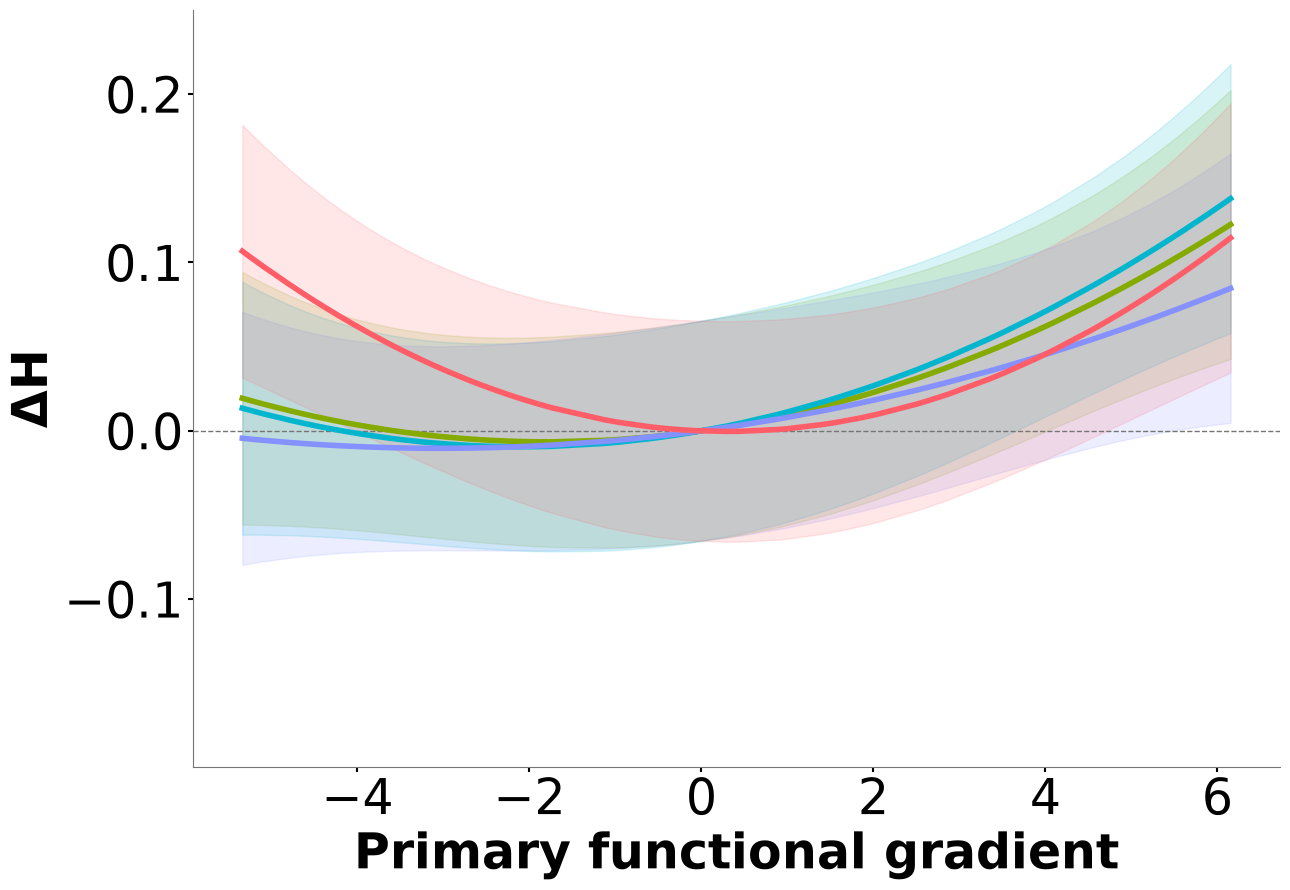

In [6]:
import pandas as pd
import numpy as np

preds = pd.read_csv(f"{base_path}/RESULTS/replication_dataset/models/margulies_model_interaction.csv")

task_intercepts = {}

for task, sub in preds.groupby("group"):

    sub = sub.sort_values("x")

    task_intercepts[task] = np.interp(
        0,
        sub["x"],
        sub["predicted"]
    )

# Predictions
preds["Hursts_pred_centered"] = (
    preds["predicted"]
    - preds["group"].map(task_intercepts)
)

# Confidence intervals
if {"conf.low", "conf.high"}.issubset(preds.columns):

    preds["conf.low_centered"] = (
        preds["conf.low"]
        - preds["group"].map(task_intercepts)
    )

    preds["conf.high_centered"] = (
        preds["conf.high"]
        - preds["group"].map(task_intercepts)
    )


# Plot

fig, ax = plt.subplots(figsize=figsize)

# prediction lines
levels = sorted(preds["group"].unique())

for lev in levels:

    col = task_colors.get(lev, "gray")
    label = task_names.get(lev, f"Task = {lev}")

    sub = (
        preds[preds["group"] == lev]
        .sort_values("x")
    )

    ax.plot(
        sub["x"],
        sub["Hursts_pred_centered"],
        color=col,
        label=label,
        linewidth=LINE,
        zorder=2
    )

    if {
        "conf.low_centered",
        "conf.high_centered"
    }.issubset(sub.columns):

        ax.fill_between(
            sub["x"],
            sub["conf.low_centered"],
            sub["conf.high_centered"],
            color=col,
            alpha=0.15,
            zorder=0
        )


# orizontal line
ax.axhline(
    0,
    color=AX_GREY,
    linewidth=1,
    linestyle="--",
    zorder=0
)


# Aesthetics

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_color(AX_GREY)
ax.spines["bottom"].set_color(AX_GREY)

ax.set_xlabel(
    "Primary functional gradient",
    fontsize=LABEL_FS,
    fontweight="bold"
)

ax.set_ylabel(
    "ΔH", 
    fontsize=LABEL_FS,
    fontweight="bold"
)

ax.tick_params(
    axis="both",
    labelsize=TICK_FS,
    width=1.5
)

ax.set_ylim(1.0 - 1.2, 1.45 - 1.2)
ax.set_yticks([-0.1, 0, 0.1, 0.2])


plt.tight_layout()
plt.savefig(
    f"{output_path}/D_functional_gradient_task.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()